# 01 — Discovery e qualidade dos dados

**Pergunta:** quais problemas da base mudam o resultado, e como cada um é tratado?

- Fonte: recorte `country = 'Brazil'` da WildChat-1M (`data/raw/wildchat_br.parquet`) e o volume diário global
  (`data/raw/wildchat_volume_diario.parquet`), ambos gerados por `etl/recorte_brasil.py`.
- As colunas derivadas vêm de `etl/definicoes.py`, o mesmo código da carga.
- O resumo com todos os problemas e tratamentos está no fim do notebook.

In [1]:
from estilo import AZUL, BRUTA, CRITICO, TINTA_2, TINTA_MUDA, VOLUME, aplicar, nota  # põe etl/ no path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from definicoes import criar_conversas

aplicar()
pd.set_option("display.width", 160)
con = duckdb.connect()
criar_conversas(con, BRUTA)
q = lambda sql: con.execute(sql).fetchdf()  # noqa: E731

## 1. Volume e período

In [2]:
q("""
SELECT count(*) AS conversas, count(DISTINCT hashed_ip) AS ips, count(DISTINCT conversa_id) AS ids_unicos,
       min(inicio_utc)::DATE AS inicio, max(fim_utc)::DATE AS fim
FROM conversas
""")

,conversas,ips,ids_unicos,inicio,fim
0,11621,2385,11621,2023-04-09,2024-04-29


O Brasil tem 11.621 conversas de 2.385 IPs em 55 semanas: **1,4% da base global**. A mediana é de 41 novos
usuários por semana. Esse tamanho limita a precisão de qualquer recorte semanal (ver notebook 03).

## 2. Falhas de coleta
Um dia sem dados pode ser falha de coleta, não falta de uso. O Brasil sozinho tem poucos dados por dia,
então o teste usa o volume **global**.

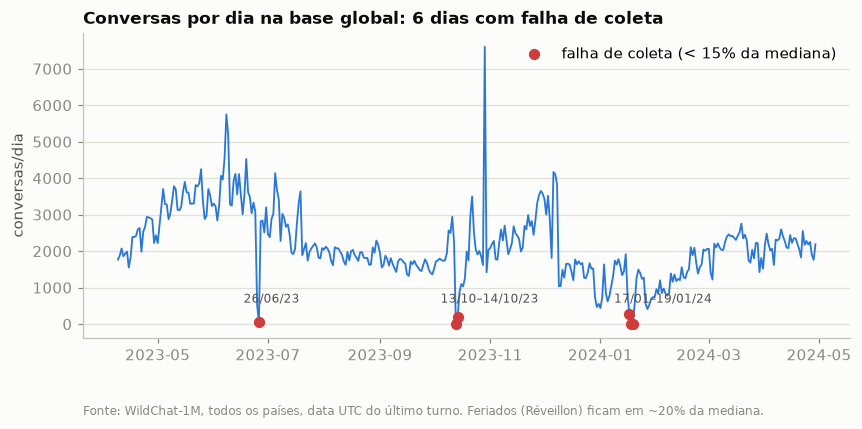

,dia_utc,conversas,fracao_mediana
78,2023-06-26,64,0.031181
187,2023-10-13,0,0.000000
188,2023-10-14,187,0.091108
283,2024-01-17,268,0.130572
284,2024-01-18,0,0.000000
285,2024-01-19,0,0.000000


In [3]:
vol = q(f"""
WITH v AS (SELECT * FROM read_parquet('{VOLUME}')),
cal AS (SELECT unnest(generate_series(DATE '2023-04-09', DATE '2024-04-29', INTERVAL 1 DAY))::DATE AS dia_utc)
SELECT dia_utc, coalesce(conversas, 0) AS conversas,
       coalesce(conversas, 0) / (SELECT median(conversas) FROM v) AS fracao_mediana
FROM cal LEFT JOIN v USING (dia_utc) ORDER BY 1
""")
lacunas = vol[vol.fracao_mediana < 0.15]
fig, ax = plt.subplots()
ax.plot(vol.dia_utc, vol.conversas, color=AZUL, lw=1.2)
ax.scatter(lacunas.dia_utc, lacunas.conversas, color=CRITICO, s=40, zorder=3, label="falha de coleta (< 15% da mediana)")
# um rótulo por bloco de dias vizinhos, para não sobrepor
blocos = (lacunas.dia_utc.diff().dt.days.fillna(99) > 1).cumsum()
for _, g in lacunas.groupby(blocos):
    rotulo = f"{g.dia_utc.min():%d/%m}" + (f"–{g.dia_utc.max():%d/%m}" if len(g) > 1 else "") + f"/{g.dia_utc.min():%y}"
    ax.annotate(rotulo, (g.dia_utc.min(), 0), xytext=(-10, 14), textcoords="offset points", fontsize=8,
                color=TINTA_2)
ax.set_title("Conversas por dia na base global: 6 dias com falha de coleta")
ax.set_ylabel("conversas/dia")
ax.legend(loc="upper right")
nota(ax, "Fonte: WildChat-1M, todos os países, data UTC do último turno. Feriados (Réveillon) ficam em ~20% da mediana.")
plt.show()
lacunas

**Achado:** em 13/10/2023 e 18–19/01/2024 não há nenhuma conversa no mundo. Os dias vizinhos (26/06, 14/10,
17/01) têm menos de 15% do normal. Isso é falha de coleta.

**Tratamento (BDR-006):** a pessoa cuja janela de 7 dias cobre um desses dias pode ter voltado sem registro.
Ela sai do denominador da taxa. São 87 pessoas (3,8% das observáveis). A taxa total não muda (28,6% com e sem
a exclusão), mas as coortes das semanas afetadas ficam corretas.

## 3. Chave da conversa

In [4]:
q(f"""
WITH h AS (SELECT conversation_hash, count(*) n, count(DISTINCT hashed_ip) ips
           FROM read_parquet('{BRUTA}') GROUP BY 1 HAVING count(*) > 1)
SELECT count(*) AS hashes_repetidos, sum(n) AS conversas, count(*) FILTER (ips = 1) AS mesmo_ip FROM h
""")

,hashes_repetidos,conversas,mesmo_ip
0,27,93.0,0


`conversation_hash` repete em 93 conversas, sempre de IPs diferentes: é o mesmo texto ("oi", prompts
copiados) enviado por pessoas diferentes. **Tratamento:** a chave é o `turn_identifier` do 1º turno,
que é único. Não há deduplicação.

## 4. Horários
- Turnos do usuário **nunca** têm horário; turnos do assistente sempre têm.
- O `timestamp` de topo é sempre o maior horário dos turnos (o último), e nenhum turno está fora de ordem.

In [5]:
q("""
SELECT quantile_cont(epoch(fim_utc - inicio_utc) / 60, 0.5)  AS duracao_mediana_min,
       quantile_cont(epoch(fim_utc - inicio_utc) / 60, 0.9)  AS duracao_p90_min,
       max(epoch(fim_utc - inicio_utc) / 3600)              AS duracao_max_h,
       count(*) FILTER (fim_utc - inicio_utc > INTERVAL 1 HOUR) AS duram_mais_1h,
       count(*) FILTER (timezone('America/Sao_Paulo', inicio_utc)::DATE
                        <> timezone('America/Sao_Paulo', fim_utc)::DATE) AS atravessam_meia_noite_sp
FROM conversas
""")

,duracao_mediana_min,duracao_p90_min,duracao_max_h,duram_mais_1h,atravessam_meia_noite_sp
0,0.0,21.166667,271.590556,546,124


**Achado:** 546 conversas duram mais de 1 hora, e a mais longa dura 11 dias. A pessoa deixa a aba aberta e
continua a mesma conversa outro dia. Essa continuação também é uso.

**Tratamento (BDR-002):**
- O início da conversa é o horário da 1ª resposta do assistente. Nunca é o `timestamp` de topo.
- A sessão é montada com **cada resposta** do assistente, e não só com o início de cada conversa.
- Com isso, 96 pessoas passam a contar como retorno: a taxa vai de 24,3% para 28,6%.

## 5. Usuário: concentração e IPs compartilhados

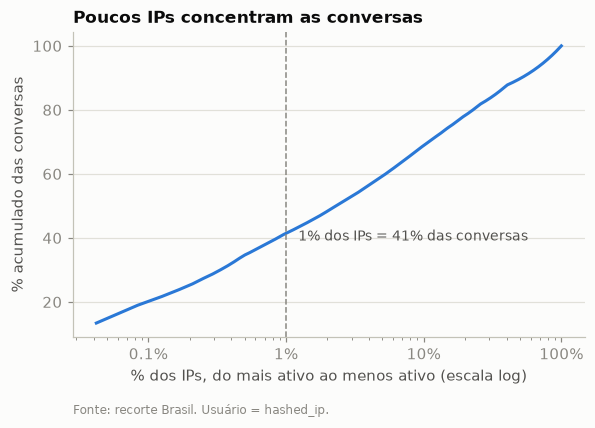

IPs por nº de user-agents: {1: 2116, 2: 166, 3: 55, 4: 20, 5: 13, 6: 10, 7: 2, 11: 3}


,conversas,user_agents,dias_ativos,pct_ips,pct_conversas
0,1557,35,129,0.041929,13.398159
1,648,2,22,0.083857,18.974271
2,319,2,28,0.125786,21.719301
3,249,4,49,0.167715,23.861974
4,207,1,11,0.209644,25.643232


In [6]:
ips = q("""
SELECT hashed_ip, count(*) AS conversas, count(DISTINCT user_agent) AS user_agents,
       count(DISTINCT timezone('America/Sao_Paulo', inicio_utc)::DATE) AS dias_ativos
FROM conversas GROUP BY 1 ORDER BY conversas DESC
""")
ips["pct_ips"] = (ips.index + 1) / len(ips) * 100
ips["pct_conversas"] = ips.conversas.cumsum() / ips.conversas.sum() * 100
top1 = ips[ips.pct_ips <= 1].conversas.sum() / ips.conversas.sum() * 100
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(ips.pct_ips, ips.pct_conversas, color=AZUL)
ax.axvline(1, color=TINTA_MUDA, lw=1, ls="--")
ax.annotate(f"1% dos IPs = {top1:.0f}% das conversas", (1, top1), xytext=(8, -4), textcoords="offset points",
            fontsize=9, color=TINTA_2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}%"))
ax.set_xlabel("% dos IPs, do mais ativo ao menos ativo (escala log)")
ax.set_ylabel("% acumulado das conversas")
ax.set_title("Poucos IPs concentram as conversas")
nota(ax, "Fonte: recorte Brasil. Usuário = hashed_ip.")
plt.show()
print("IPs por nº de user-agents:", ips.user_agents.clip(upper=11).value_counts().sort_index().to_dict())
ips.head(5).drop(columns="hashed_ip")

**Achados:**
- 60% dos IPs têm **uma única conversa**; 1% dos IPs gera 41% das conversas.
- 89% dos IPs têm um só user-agent. Três IPs têm mais de 10 user-agents e somam 16% das conversas.
  O maior tem 1.557 conversas, 35 user-agents e 129 dias ativos: é um IP compartilhado (escola, empresa
  ou proxy).

**Tratamento (BDR-001):**
- Na taxa de retorno, cada IP conta uma vez. IP compartilhado mexe pouco na taxa: excluir os três muda
  −0,1 p.p.
- Nas análises por **conversa** (temas, modelos), os IPs com mais de 10 user-agents ficam marcados. Assim
  não dominam as distribuições.

## 6. User-agent, dispositivo e IP dinâmico

In [7]:
q(r"""
SELECT count(*) FILTER (regexp_matches(lower(user_agent),
         'python|curl|okhttp|axios|go-http|bot|spider|crawl|headless|postman|node-fetch|java/|aiohttp|httpx|wget')) AS ua_robo,
       round(100 * avg(regexp_matches(user_agent, 'Mobile|Android|iPhone|iPad')::INT), 1) AS pct_mobile,
       count(DISTINCT user_agent) AS user_agents_distintos
FROM conversas
""")

,ua_robo,pct_mobile,user_agents_distintos
0,0,36.2,436


In [8]:
q("""
WITH ua_ips AS (SELECT user_agent, count(DISTINCT hashed_ip) AS n_ips FROM conversas GROUP BY 1),
f AS (SELECT hashed_ip, min(inicio_utc) t0, arg_min(user_agent, inicio_utc) ua, arg_min(accept_language, inicio_utc) al
      FROM conversas GROUP BY 1)
SELECT count(*) AS novos_ips,
       count(*) FILTER (ua IN (SELECT user_agent FROM ua_ips WHERE n_ips <= 3) AND EXISTS (
           SELECT 1 FROM conversas c WHERE c.user_agent = f.ua AND c.accept_language = f.al
             AND c.hashed_ip <> f.hashed_ip AND c.inicio_utc BETWEEN f.t0 - INTERVAL 7 DAY AND f.t0
       )) AS ua_raro_visto_em_outro_ip_7d
FROM f
""")

,novos_ips,ua_raro_visto_em_outro_ip_7d
0,2385,48


**Achados:**
- Nenhum user-agent de robô ou biblioteca. 36% das conversas vêm de celular.
- Só há 436 user-agents distintos no Brasil. Por isso o user-agent não identifica a pessoa.
- **IP dinâmico** (operadora troca o IP da mesma pessoa): 48 novos IPs (2%) têm um user-agent raro já
  visto em outro IP na semana anterior. Esse valor é um **limite inferior**. O dado não permite medir o
  valor real.

**Tratamento:** registrar como risco (`docs/RISCOS.md`). IP dinâmico separa uma pessoa em duas e
**subestima** o retorno. O efeito tende a ser maior no celular.

## 7. Idioma, estado e conteúdo

In [9]:
display(q("SELECT idioma, count(*) AS conversas FROM conversas GROUP BY 1 ORDER BY 2 DESC LIMIT 8"))
display(q("""
SELECT count(*) FILTER (usuarios < 20) AS estados_com_menos_de_20_usuarios, count(*) AS estados,
       sum(usuarios) FILTER (usuarios < 20) AS usuarios_nesses_estados
FROM (SELECT estado, count(DISTINCT hashed_ip) AS usuarios FROM conversas GROUP BY 1)
"""))
q("""
SELECT count(*) FILTER (sem_conteudo) AS sem_nenhuma_msg, count(*) FILTER (primeira_msg_vazia) AS primeira_msg_vazia,
       count(*) FILTER (redacted) AS com_pii_mascarada, count(*) FILTER (toxic) AS toxicas,
       count(*) FILTER (estado IS NULL) AS sem_estado
FROM conversas
""")

,idioma,conversas
0,Portuguese,8797
1,English,1868
2,Spanish,158
3,Japanese,129
4,Latin,88
5,Nolang,83
6,Finnish,65
7,French,43


,estados_com_menos_de_20_usuarios,estados,usuarios_nesses_estados
0,10,28,111.0


,sem_nenhuma_msg,primeira_msg_vazia,com_pii_mascarada,toxicas,sem_estado
0,76,141,56,0,51


**Achados e tratamentos:**
- **Idioma:** 76% português, 16% inglês. "Latin", "Finnish" e "Nolang" aparecem em mensagens curtas
  ("oi"): é ruído do detector. O idioma entra como fator só em 3 níveis (português, inglês, outro).
- **Estado:** 10 de 28 valores têm menos de 20 usuários. Pela regra de k-anonimato (k = 20, ADR-007), o
  dashboard agrupa esses estados em "outros".
- **Conteúdo vazio:** 76 conversas não têm nenhuma mensagem do usuário (bug do coletor). Elas não contam
  como uso (BDR-008). Outras 65 têm só a 1ª mensagem vazia: o classificador marca essas como
  `saudacao_teste`, sem chamar o LLM.
- **Tóxicas:** zero, porque a versão pública removeu as conversas tóxicas. Isso cria buracos no histórico:
  um retorno tóxico some e o retorno fica **subestimado**. O fator "toxicidade" não pode ser medido.
- **PII mascarada:** 56 conversas. O texto nunca vai para a base analítica.

## 8. Intervalo entre atividades (base da definição de sessão)

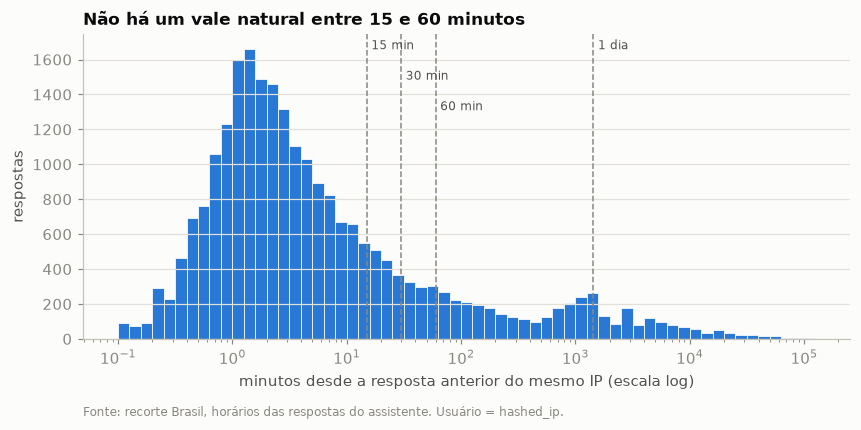

In [10]:
gaps = q(f"""
WITH e AS (
    SELECT hashed_ip, unnest(list_transform(list_filter(conversation, lambda c: c.role = 'assistant'),
                                            lambda c: c.timestamp)) AS ts
    FROM read_parquet('{BRUTA}')
)
SELECT epoch(ts - lag(ts) OVER (PARTITION BY hashed_ip ORDER BY ts)) / 60 AS gap_min FROM e
""").dropna()
fig, ax = plt.subplots()
bins = [10 ** (i / 10) for i in range(-10, 52)]
ax.hist(gaps.gap_min.clip(lower=0.1), bins=bins, color=AZUL, edgecolor="white", linewidth=0.5)
topo = ax.get_ylim()[1]
for m, rot, alt in [(15, "15 min", 0.95), (30, "30 min", 0.85), (60, "60 min", 0.75), (60 * 24, "1 dia", 0.95)]:
    ax.axvline(m, color=TINTA_MUDA, lw=1, ls="--")
    ax.annotate(rot, (m, topo * alt), xytext=(3, 0), textcoords="offset points", fontsize=8, color=TINTA_2)
ax.set_xscale("log")
ax.set_xlabel("minutos desde a resposta anterior do mesmo IP (escala log)")
ax.set_ylabel("respostas")
ax.set_title("Não há um vale natural entre 15 e 60 minutos")
nota(ax, "Fonte: recorte Brasil, horários das respostas do assistente. Usuário = hashed_ip.")
plt.show()

**Achados:**
- A distribuição cai de forma contínua entre 15 e 60 minutos, sem um vale que separe as sessões de forma
  natural.
- Há um pico perto de **1 dia**: quem volta tende a voltar no mesmo horário do dia seguinte. É um sinal de
  hábito, útil para lembretes no produto.

**Tratamento (BDR-002):** usar 30 minutos, a convenção de mercado (padrão de
ferramentas de web analytics). A análise de sensibilidade mostra o custo dessa escolha: 15 min dá
+5,4 p.p. e 60 min dá −3,5 p.p.

## Resumo: problemas e tratamentos

| # | Problema | Volume | Tratamento | Registro |
|---|---|---|---|---|
| 1 | Falha de coleta global | 6 dias; 87 pessoas com a janela afetada | Sai do denominador | BDR-006 |
| 2 | `conversation_hash` não é único | 93 conversas | Chave = `turn_identifier` do 1º turno | — |
| 3 | Turno do usuário sem horário | 100% | Início = 1ª resposta do assistente | BDR-002 |
| 4 | Conversa continua em outro dia | 546 conversas > 1h | Sessão por resposta (turno) | BDR-002 |
| 5 | IP compartilhado | 3 IPs, 16% das conversas | Marca nas análises por conversa | BDR-001 |
| 6 | IP dinâmico | ≥ 2% dos novos IPs | Risco registrado; retorno subestimado | BDR-001, RISCOS |
| 7 | Conversa sem conteúdo | 76 conversas | Não conta como uso | BDR-008 |
| 8 | Tóxicas removidas na origem | desconhecido | Risco registrado; fator não medido | RISCOS |
| 9 | Estado com < 20 usuários | 10 de 28 valores | Agrupa em "outros" | ADR-007 |
| 10 | Ruído do detector de idioma | ~3% | Fator idioma em 3 níveis | BDR-009 |